# Fuel Consumption and CO₂ Emissions Analysis

## Project Overview

This project analyzes vehicle fuel consumption, fuel efficiency, engine characteristics, vehicle classes, fuel types, manufacturers, and CO₂ emissions.

The objective is to identify patterns and relationships between vehicle characteristics, fuel consumption, and environmental impact.

## Dataset

The dataset contains information about 1,067 vehicles and 13 features including:

- Engine Size
- Cylinders
- Transmission
- Fuel Type
- Fuel Consumption
- Fuel Efficiency
- CO₂ Emissions
- Vehicle Class
- Manufacturer

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("FuelConsumption.csv")
df


,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1062,2014,VOLVO,XC60 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1063,2014,VOLVO,XC60 AWD,SUV - SMALL,3.2,6,AS6,X,13.2,9.5,11.5,25,264
1064,2014,VOLVO,XC70 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1065,2014,VOLVO,XC70 AWD,SUV - SMALL,3.2,6,AS6,X,12.9,9.3,11.3,25,260


## Libraries Used

- Pandas – data manipulation and analysis
- NumPy – numerical operations
- Matplotlib – data visualization
- Seaborn – statistical visualization

In [8]:
df.shape

(1067, 13)

In [9]:
df.columns

Index(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   object 
 2   MODEL                     1067 non-null   object 
 3   VEHICLECLASS              1067 non-null   object 
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   object 
 7   FUELTYPE                  1067 non-null   object 
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 108.5+ KB


## Dataset Overview

The dataset contains 1,067 vehicle records and 13 columns.

It includes information about vehicle specifications, fuel consumption, fuel efficiency, and CO₂ emissions.

## Basic Data Understanding

In [11]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [12]:
# Numerical columns
df.describe(include=np.number)

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [13]:
# Categorical columns
df.describe(include="object")

,MAKE,MODEL,VEHICLECLASS,TRANSMISSION,FUELTYPE
count,1067,1067,1067,1067,1067
unique,39,663,16,22,4
top,FORD,F150 FFV,MID-SIZE,A6,X
freq,90,8,178,222,514


In [45]:
#Unique values
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

MODELYEAR: 1 unique values
MAKE: 39 unique values
MODEL: 663 unique values
VEHICLECLASS: 16 unique values
ENGINESIZE: 45 unique values
CYLINDERS: 7 unique values
TRANSMISSION: 22 unique values
FUELTYPE: 4 unique values
FUELCONSUMPTION_CITY: 167 unique values
FUELCONSUMPTION_HWY: 118 unique values
FUELCONSUMPTION_COMB: 148 unique values
FUELCONSUMPTION_COMB_MPG: 43 unique values
CO2EMISSIONS: 159 unique values


In [15]:
# Missing Values
df.isnull().sum()

MODELYEAR                   0
MAKE                        0
MODEL                       0
VEHICLECLASS                0
ENGINESIZE                  0
CYLINDERS                   0
TRANSMISSION                0
FUELTYPE                    0
FUELCONSUMPTION_CITY        0
FUELCONSUMPTION_HWY         0
FUELCONSUMPTION_COMB        0
FUELCONSUMPTION_COMB_MPG    0
CO2EMISSIONS                0
dtype: int64

In [16]:
# Total
df.isnull().sum().sum()

np.int64(0)

## Missing Value Analysis

No missing values were found in the dataset. Therefore, no missing-value imputation was required.

In [17]:
# Duplicate Check
df.duplicated().sum()

np.int64(0)

In [18]:
# If duplicates found
df = df.drop_duplicates()

In [19]:
df.shape

(1067, 13)

## Duplicate Value Analysis

Duplicate records were checked to ensure that each vehicle record is represented only once.

In [20]:
#Data Type Validation
df.dtypes

MODELYEAR                     int64
MAKE                         object
MODEL                        object
VEHICLECLASS                 object
ENGINESIZE                  float64
CYLINDERS                     int64
TRANSMISSION                 object
FUELTYPE                     object
FUELCONSUMPTION_CITY        float64
FUELCONSUMPTION_HWY         float64
FUELCONSUMPTION_COMB        float64
FUELCONSUMPTION_COMB_MPG      int64
CO2EMISSIONS                  int64
dtype: object

## Data Type Validation

The numerical and categorical columns were checked to ensure that each feature has an appropriate data type for analysis.

## Data Dictionary

| Column | Description |
|---|---|
| MODELYEAR | Vehicle model year |
| MAKE | Vehicle manufacturer |
| MODEL | Vehicle model |
| VEHICLECLASS | Vehicle category |
| ENGINESIZE | Engine displacement in litres |
| CYLINDERS | Number of cylinders |
| TRANSMISSION | Transmission type |
| FUELTYPE | Type of fuel |
| FUELCONSUMPTION_CITY | City fuel consumption |
| FUELCONSUMPTION_HWY | Highway fuel consumption |
| FUELCONSUMPTION_COMB | Combined fuel consumption |
| FUELCONSUMPTION_COMB_MPG | Combined fuel efficiency |
| CO2EMISSIONS | CO₂ emissions in g/km |

In [46]:
# KPI Summary
print("Total Vehicles:", df.shape[0])
print("Total Manufacturers:", df["MAKE"].nunique())
print("Total Vehicle Classes:", df["VEHICLECLASS"].nunique())
print("Total Fuel Types:", df["FUELTYPE"].nunique())

print("Average Engine Size:",
      round(df["ENGINESIZE"].mean(), 2))

print("Average MPG:",
      round(df["FUELCONSUMPTION_COMB_MPG"].mean(), 2))

print("Average CO₂ Emissions:",
      round(df["CO2EMISSIONS"].mean(), 2))

Total Vehicles: 1067
Total Manufacturers: 39
Total Vehicle Classes: 16
Total Fuel Types: 4
Average Engine Size: 3.35
Average MPG: 26.44
Average CO₂ Emissions: 256.23


In [ ]:
# CO₂ Distribution — Histogram
plt.figure(figsize=(10,6))

sns.histplot(
    df["CO2EMISSIONS"],
    bins=30,
    kde=True
)

plt.title("Distribution of CO₂ Emissions")
plt.xlabel("CO₂ Emissions (g/km)")
plt.ylabel("Number of Vehicles")

plt.show()

### Key Insight

The distribution shows that most vehicles fall within the middle range of CO₂ emissions, while a smaller number of vehicles have substantially higher emission levels.

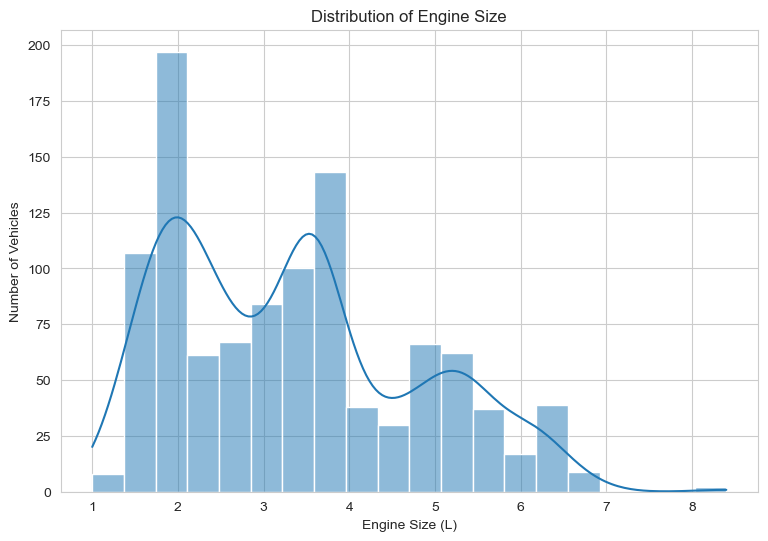

In [47]:
# Engine Size Distribution
plt.figure(figsize=(9,6))

sns.histplot(
    df["ENGINESIZE"],
    bins=20,
    kde=True
)

plt.title("Distribution of Engine Size")
plt.xlabel("Engine Size (L)")
plt.ylabel("Number of Vehicles")

plt.show()

### Key Insights: Distribution of Engine Size

* **Right-Skewed Distribution:** Most vehicles concentrate in the 1.5 L – 3.5 L range, with a long right tail extending up to 8.4 L.
* **Dominant Peak (~2.0 L):** The highest frequency occurs around 2.0 L (~195 vehicles), typical for standard 4-cylinder passenger cars.
* **Secondary Modes (~3.5 L & ~5.0 L):** Clear secondary clusters appear at ~3.5 L (~140 vehicles, V6 engines) and ~5.0 L–5.3 L (~65 vehicles, V8 engines).
* **Sparse Extremes:** Engines larger than 6.0 L are rare outliers, representing high-performance sports cars and heavy-duty vehicles.

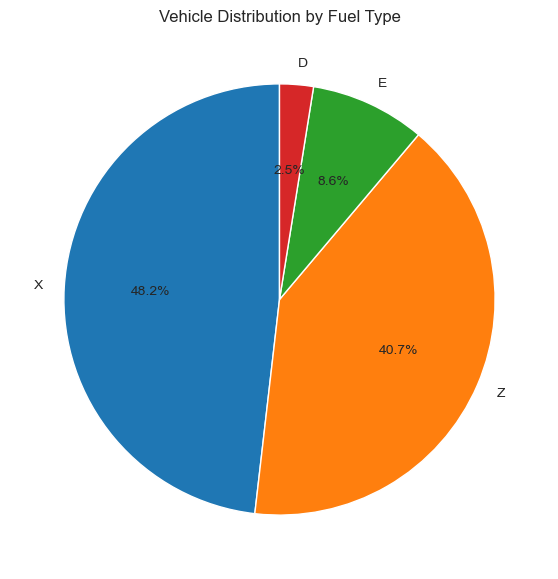

In [49]:
#Pie Chart
fuel_counts = df["FUELTYPE"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    fuel_counts,
    labels=fuel_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Vehicle Distribution by Fuel Type")

plt.show()

### Key Insights: Vehicle Distribution by Fuel Type

* **Gasoline Dominance (~88.9%):** Standard regular gasoline (**X** at 48.2%) and premium gasoline (**Z** at 40.7%) account for the vast majority of all vehicles in the dataset.
* **Alternative Fuels are Minor (~11.1%):** Ethanol/Flex-fuel (**E**) represents a moderate share at 8.6%, while Diesel (**D**) accounts for just 2.5%.
* **Low Fuel Diversity:** The market heavily relies on traditional petroleum fuels, with alternative or non-gasoline options comprising only a small fraction of the lineup.

In [25]:
vehicle_class_analysis = df.groupby("VEHICLECLASS").agg(
    Vehicle_Count=("VEHICLECLASS", "count"),
    Average_MPG=("FUELCONSUMPTION_COMB_MPG", "mean"),
    Average_CO2=("CO2EMISSIONS", "mean"),
    Average_Fuel_Consumption=("FUELCONSUMPTION_COMB", "mean")
).reset_index()

vehicle_class_analysis = vehicle_class_analysis.round(2)

display(vehicle_class_analysis)

,VEHICLECLASS,Vehicle_Count,Average_MPG,Average_CO2,Average_Fuel_Consumption
0,COMPACT,172,31.15,216.72,9.51
1,FULL-SIZE,86,24.02,267.65,12.16
2,MID-SIZE,178,30.33,226.48,9.94
3,MINICOMPACT,47,28.96,235.55,10.24
4,MINIVAN,14,23.57,260.14,12.39
5,PICKUP TRUCK - SMALL,12,23.17,284.25,12.36
6,PICKUP TRUCK - STANDARD,62,19.35,309.10,14.96
7,SPECIAL PURPOSE VEHICLE,7,27.86,235.29,10.23
8,STATION WAGON - MID-SIZE,6,30.17,235.67,10.25
9,STATION WAGON - SMALL,36,30.86,221.11,9.51


In [26]:
best_class = vehicle_class_analysis.loc[
    vehicle_class_analysis["Average_MPG"].idxmax()
]

worst_class = vehicle_class_analysis.loc[
    vehicle_class_analysis["Average_MPG"].idxmin()
]

print("Most Fuel-Efficient Class:")
display(best_class)

print("Least Fuel-Efficient Class:")
display(worst_class)

Most Fuel-Efficient Class:


VEHICLECLASS                COMPACT
Vehicle_Count                   172
Average_MPG                   31.15
Average_CO2                  216.72
Average_Fuel_Consumption       9.51
Name: 0, dtype: object

Least Fuel-Efficient Class:


VEHICLECLASS                VAN - PASSENGER
Vehicle_Count                            25
Average_MPG                            14.2
Average_CO2                           401.0
Average_Fuel_Consumption              20.33
Name: 15, dtype: object

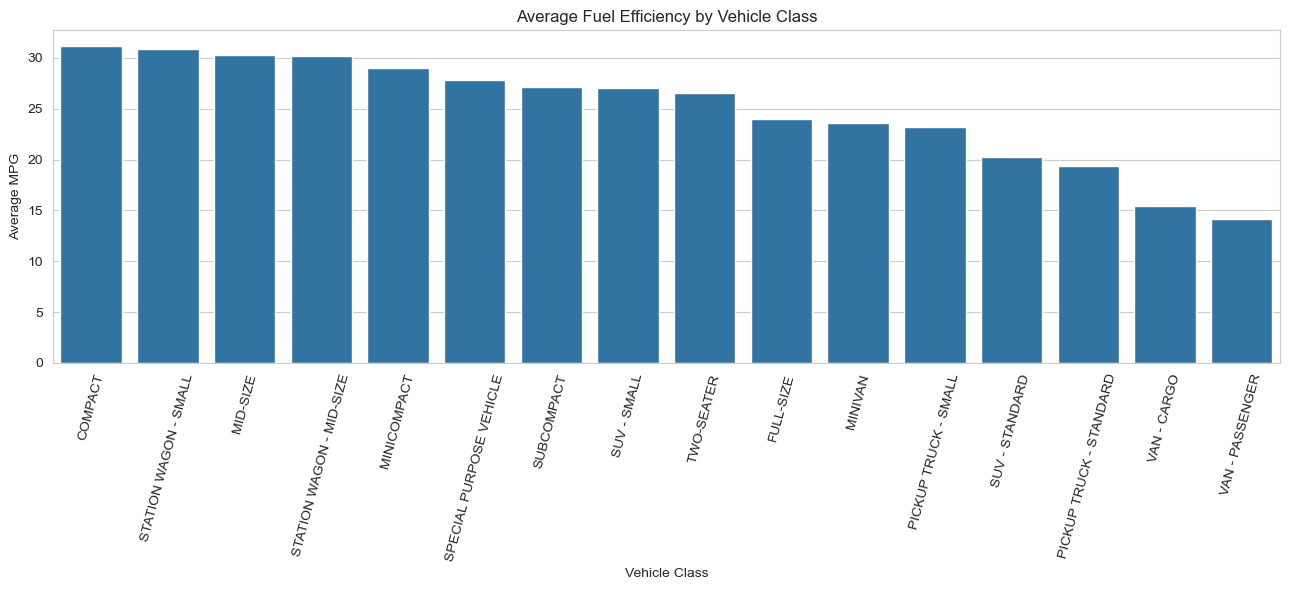

In [27]:
plot_data = vehicle_class_analysis.sort_values(
    "Average_MPG",
    ascending=False
)

plt.figure(figsize=(13,6))

sns.barplot(
    data=plot_data,
    x="VEHICLECLASS",
    y="Average_MPG"
)

plt.title("Average Fuel Efficiency by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Average MPG")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

### Key Insights: Average Fuel Efficiency by Vehicle Class

* **Top Performers (Compact & Wagons):** **COMPACT** leads overall efficiency at **31.15 MPG** (9.51 L/100 km), closely followed by **STATION WAGON - SMALL** (30.86 MPG) and **MID-SIZE** (30.33 MPG).
* **Least Efficient (Vans & Large Trucks):** **VAN - PASSENGER** has the worst efficiency at **14.20 MPG** (20.33 L/100 km), followed by **VAN - CARGO** (15.41 MPG) and **PICKUP TRUCK - STANDARD** (19.35 MPG).
* **Vehicle Size Trade-Off:** Efficiency decreases sharply as vehicle size and weight increase—passenger cars consistently exceed **26–31 MPG**, whereas standard SUVs, full-size trucks, and vans fall near or below **20 MPG**.
* **CO₂ Inverse Correlation:** Fuel efficiency directly mirrors emissions; the top-performing compacts average **~217 g/km CO₂**, while passenger vans emit nearly double at **401 g/km CO₂**.

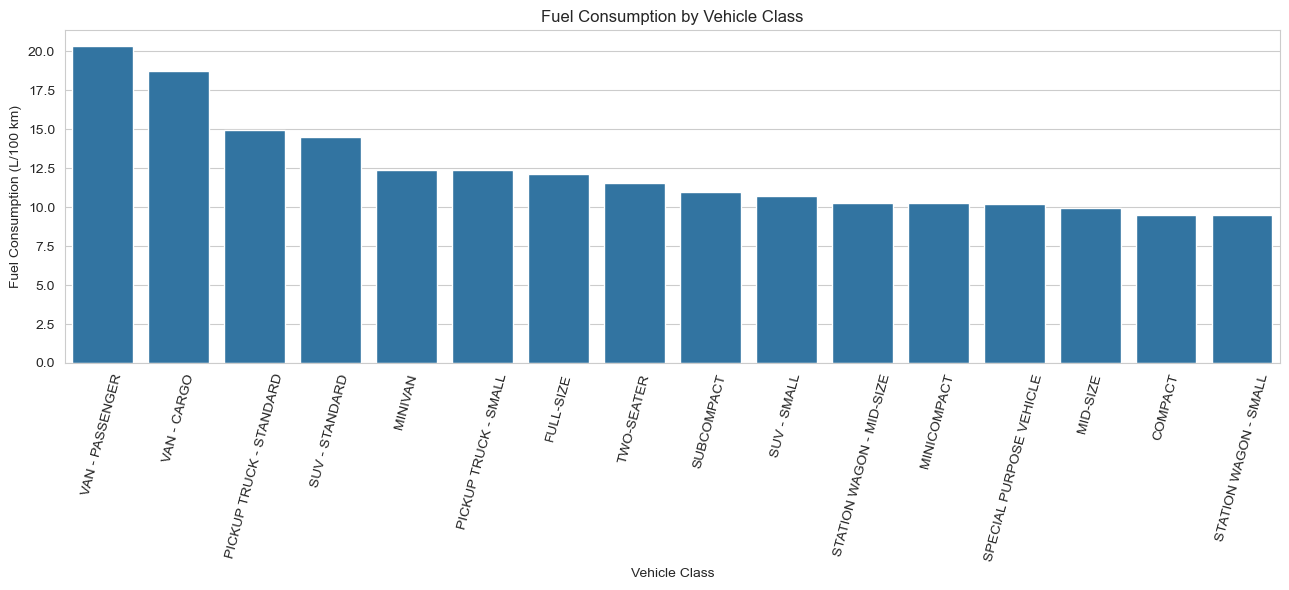

In [28]:
plt.figure(figsize=(13,6))

sns.barplot(
    data=plot_data.sort_values(
        "Average_Fuel_Consumption",
        ascending=False
    ),
    x="VEHICLECLASS",
    y="Average_Fuel_Consumption"
)

plt.title("Fuel Consumption by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Fuel Consumption (L/100 km)")

plt.xticks(rotation=75)
plt.tight_layout()

plt.show()

### Key Insights: Fuel Consumption by Vehicle Class

* **Highest Consumers (Vans & Large Trucks):** **VAN - PASSENGER** consumes the most fuel at **~20.3 L/100 km**, followed closely by **VAN - CARGO** (~18.6 L/100 km) and **PICKUP TRUCK - STANDARD** (~14.8 L/100 km).
* **Lowest Consumers (Sedans & Wagons):** **COMPACT**, **MID-SIZE**, and **STATION WAGON - SMALL** are the most economical, averaging below **10.0 L/100 km** (~9.4–9.5 L/100 km).
* **Mid-Tier Segment (10–13 L/100 km):** Crossovers, subcompacts, and full-size sedans fall into a moderate bracket, ranging between **SUV - SMALL** (~10.5 L/100 km) and **SUV - STANDARD** / **MINIVAN** (~12.2–14.3 L/100 km).
* **Direct Size/Utility Penalty:** Commercial and heavy-utility body styles consume more than double the fuel per 100 km compared to compact passenger vehicles.

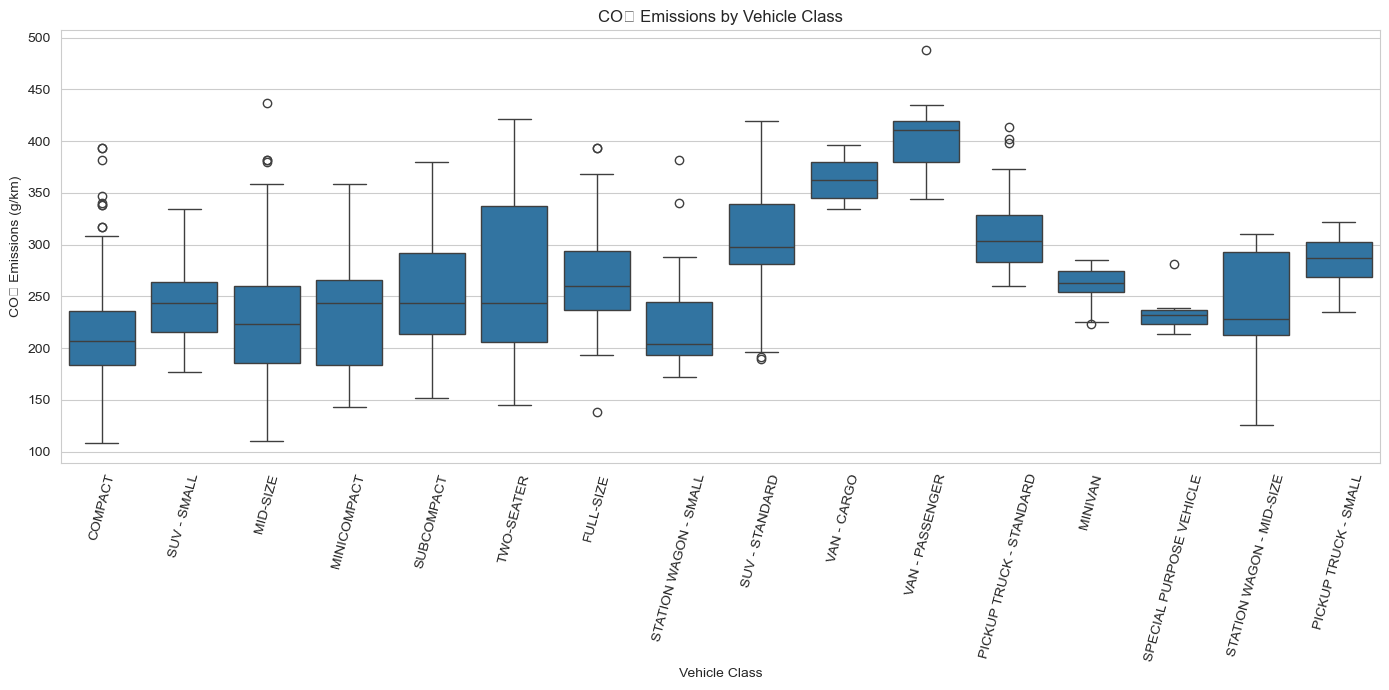

In [29]:
plt.figure(figsize=(14,7))

sns.boxplot(
    data=df,
    x="VEHICLECLASS",
    y="CO2EMISSIONS"
)

plt.title("CO₂ Emissions by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("CO₂ Emissions (g/km)")

plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

### Key Insights: CO₂ Emissions by Vehicle Class

* **Highest Emitters (Commercial & Large Vehicles):** **VAN - PASSENGER** generates the highest median emissions (~390–400 g/km), followed closely by **VAN - CARGO** (~360 g/km) and **PICKUP TRUCK - STANDARD** (~310 g/km).
* **Lowest Emitters (Small Passenger Cars):** **COMPACT**, **MID-SIZE**, and **STATION WAGON - SMALL** maintain the lowest median emissions, clustering well under **220 g/km**.
* **High Variance in Performance & SUVs:** **TWO-SEATER** and **SUV - STANDARD** show broad interquartile ranges, spanning from ~200 g/km up to over 400 g/km due to diverse powertrain offerings (efficient standard engines vs. high-output performance engines).
* **Consistent Baselines Across Sedans:** Categories like **MIN

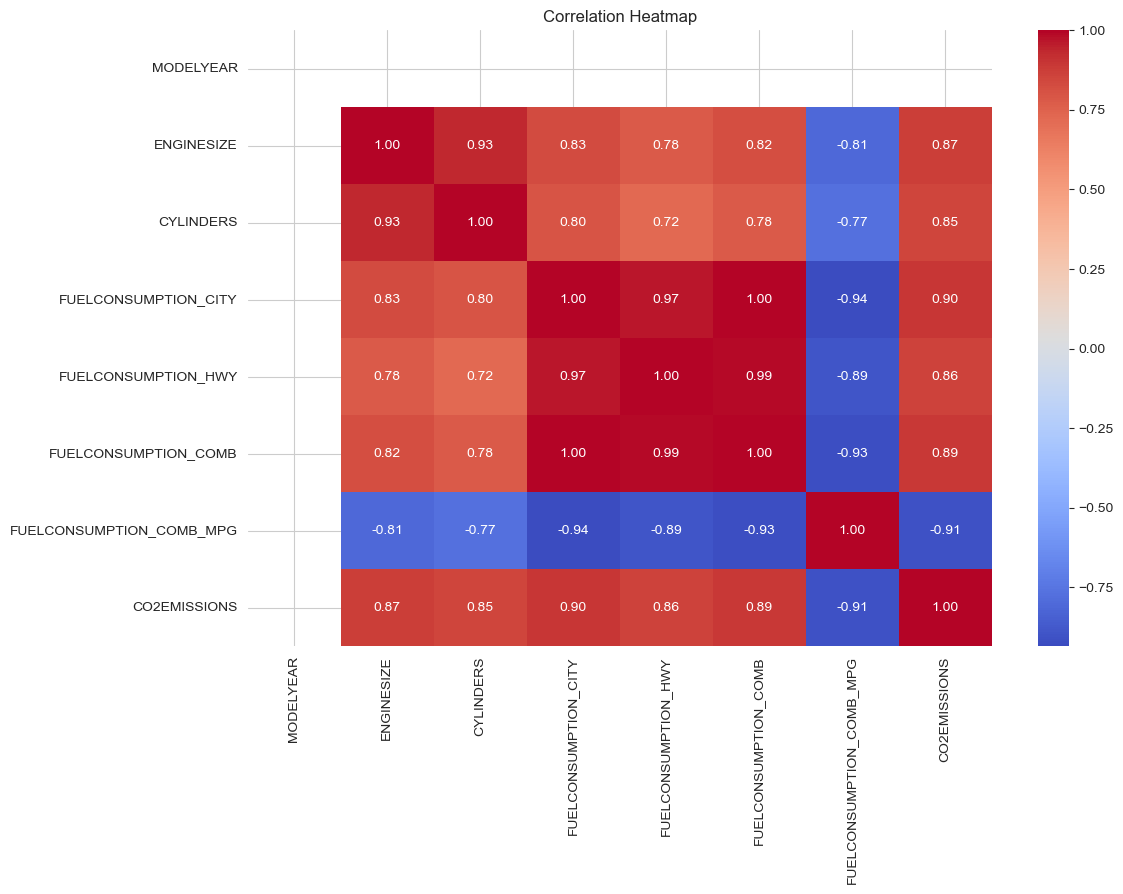

In [30]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

corr = df[numeric_cols].corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### Key Insights: Correlation Heatmap

* **Strong Positive Drivers of CO₂ Emissions:** Fuel consumption metrics (`FUELCONSUMPTION_CITY` at **0.90**, `COMB` at **0.89**, `HWY` at **0.86**) and powertrain size (`ENGINESIZE` at **0.87**, `CYLINDERS` at **0.85**) show extremely strong positive correlations with `CO2EMISSIONS`.
* **Strong Inverse Relationship with MPG:** `FUELCONSUMPTION_COMB_MPG` is strongly negatively correlated with both `CO2EMISSIONS` (**-0.91**) and combined fuel consumption in L/100 km (**-0.93**), reflecting the mathematical reciprocal nature of MPG versus L/100 km.
* **Near-Collinear Fuel Metrics:** City, highway, and combined fuel consumption figures correlate almost perfectly with one another (**0.97 to 1.00**), indicating strong multicollinearity among these features.
* **Engine Displacement & Cylinder Coupling:** `ENGINESIZE` and `CYLINDERS` have a very high correlation (**0.93**), meaning larger displacements reliably scale with cylinder counts.
* **Zero Variance in Model Year:** `MODELYEAR` shows no correlation with any feature (all **NaN/blank**), confirming it is a constant value (2014) across the entire dataset.

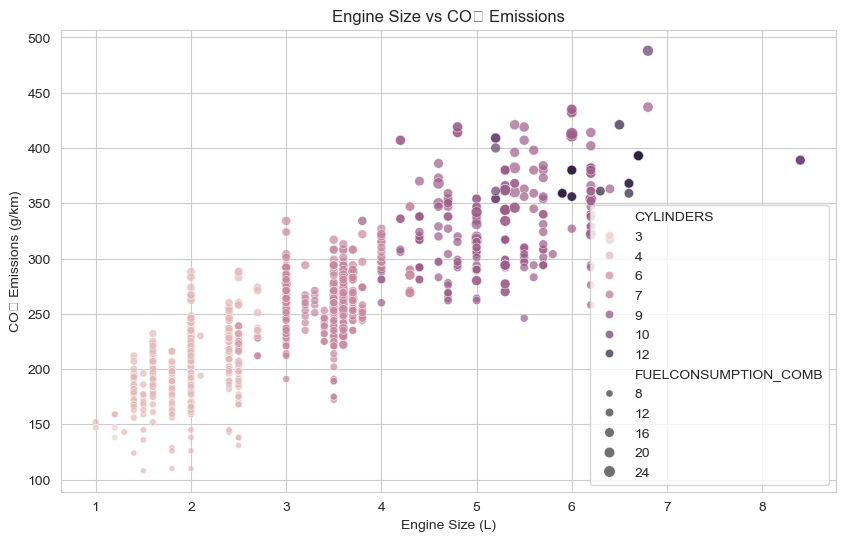

In [31]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="ENGINESIZE",
    y="CO2EMISSIONS",
    hue="CYLINDERS",
    size="FUELCONSUMPTION_COMB",
    alpha=0.7
)

plt.title("Engine Size vs CO₂ Emissions")
plt.xlabel("Engine Size (L)")
plt.ylabel("CO₂ Emissions (g/km)")

plt.show()

### Key Insights: Engine Size vs CO₂ Emissions

* **Strong Positive Linear Trend:** CO₂ emissions increase proportionally with engine size, rising from ~100–150 g/km for sub-2.0 L engines to over 400 g/km for engines exceeding 5.0 L.
* **Cylinder Count Stratification:** Higher cylinder counts systematically align with larger displacements and higher emissions—3- to 4-cylinder engines dominate under 2.5 L (<250 g/km), 6-cylinder engines cluster between 3.0 L–4.0 L (~250–350 g/km), and 8- to 12-cylinder engines drive the upper bracket (>350 g/km).
* **Fuel Consumption Scaling:** The largest bubble markers (`FUELCONSUMPTION_COMB`) correspond to high-displacement vehicles, reinforcing that poor fuel economy heavily compounds carbon output.
* **Variance at Fixed Displacements:** Vertical spreads at common sizes (such as 2.0 L, 3.5 L, and 5.0 L) reflect differences in vehicle mass, drivetrain (AWD vs. FWD), turbocharging, and fuel type.
* **Tapering High-End Outliers:** Displacements above 6.0 L are sparse and plateau near 400–450 g/km, represented by high-performance V8/V10/V12 powertrains.

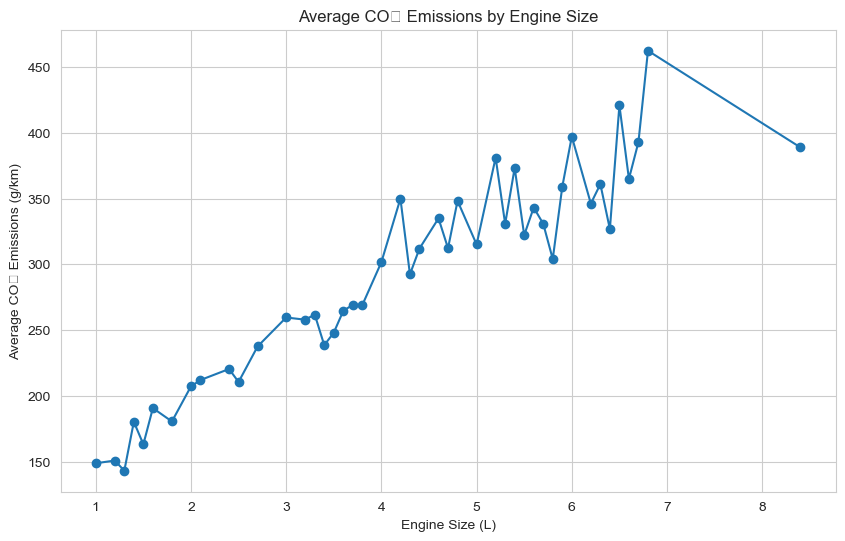

In [32]:
line_data = df.groupby(
    "ENGINESIZE"
)["CO2EMISSIONS"].mean().reset_index()

line_data = line_data.sort_values("ENGINESIZE")

plt.figure(figsize=(10,6))

plt.plot(
    line_data["ENGINESIZE"],
    line_data["CO2EMISSIONS"],
    marker="o"
)

plt.title("Average CO₂ Emissions by Engine Size")
plt.xlabel("Engine Size (L)")
plt.ylabel("Average CO₂ Emissions (g/km)")

plt.show()

### Key Insights: Average CO₂ Emissions by Engine Size

* **General Upward Trajectory:** Average CO₂ emissions rise steadily with engine displacement, climbing from ~150 g/km at 1.0 L to over 450 g/km near 6.8 L.
* **Smooth Progression in Mainstream Range (1.0 L – 3.5 L):** Below 4.0 L, the line shows a fairly consistent, predictable linear climb from ~150 g/km to ~260 g/km, reflecting standardized consumer passenger vehicle tuning.
* **Sharp Volatility & Peaks Above 4.0 L:** Beyond 4.0 L, the line exhibits steep spikes and dips (e.g., jumps at ~4.2 L, ~5.2 L, and ~6.8 L), caused by a mix of high-output sports cars, heavy-duty trucks, and varying forced-induction setups.
* **Peak Emission (~6.8 L):** The highest average CO₂ emission peak occurs around 6.8 L, reaching approximately **460 g/km**.
* **High-Displacement Drop-Off (>7.0 L):** Above 7.0 L, the curve shows a slight downward slope toward ~390 g/km at ~8.4 L, primarily driven by a small sample size of specific high-displacement performance models.

In [33]:
fuel_analysis = df.groupby("FUELTYPE").agg(
    Vehicle_Count=("FUELTYPE", "count"),
    Average_CO2=("CO2EMISSIONS", "mean"),
    Average_Fuel_Consumption=("FUELCONSUMPTION_COMB", "mean"),
    Average_MPG=("FUELCONSUMPTION_COMB_MPG", "mean")
).reset_index()

fuel_analysis = fuel_analysis.round(2)

display(fuel_analysis)

,FUELTYPE,Vehicle_Count,Average_CO2,Average_Fuel_Consumption,Average_MPG
0,D,27,227.78,8.44,34.63
1,E,92,291.09,18.19,16.11
2,X,514,241.10,10.48,28.77
3,Z,434,268.53,11.68,25.36


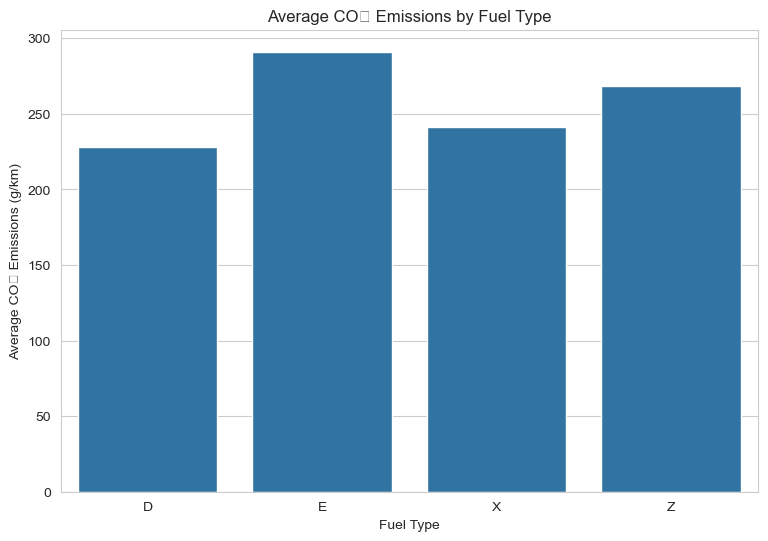

In [34]:
plt.figure(figsize=(9,6))

sns.barplot(
    data=fuel_analysis,
    x="FUELTYPE",
    y="Average_CO2"
)

plt.title("Average CO₂ Emissions by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average CO₂ Emissions (g/km)")

plt.show()

### Key Insights: Average CO₂ Emissions by Fuel Type

* **Highest Emitter — Ethanol / E85 (`E`):** Averages the highest emissions at **291.09 g/km**, driven by ethanol's lower energy density which demands significantly higher fuel consumption per kilometer (18.19 L/100 km).
* **High Output — Premium Gasoline (`Z`):** Second highest at **268.53 g/km**, reflecting its typical use in high-displacement, luxury, and high-performance vehicles.
* **Baseline — Regular Gasoline (`X`):** Averages **241.10 g/km**, representing the bulk of standard passenger commuter vehicles in the dataset.
* **Lowest Emitter — Diesel (`D`):** Produces the lowest average emissions at **227.78 g/km**, benefiting from superior thermal efficiency and lower volumetric fuel consumption (8.44 L/100 km).

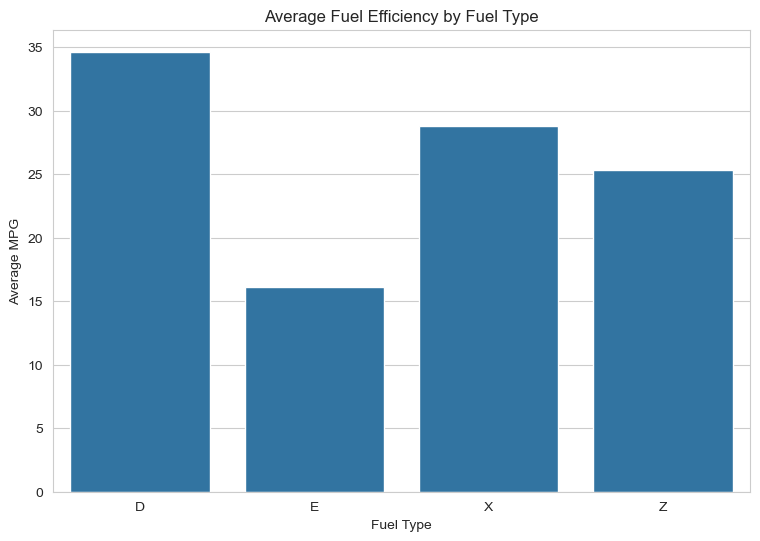

In [35]:
plt.figure(figsize=(9,6))

sns.barplot(
    data=fuel_analysis,
    x="FUELTYPE",
    y="Average_MPG"
)

plt.title("Average Fuel Efficiency by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average MPG")

plt.show()

### Key Insights: Average Fuel Efficiency by Fuel Type

* **Highest Efficiency — Diesel (`D`):** Leads all categories at **~34.5 MPG**, demonstrating the superior energy density and thermodynamic efficiency of diesel powertrains.
* **Mid-Tier Standard Fuels (`X` & `Z`):** Regular gasoline (**`X`**) averages **~28.7 MPG**, followed by premium gasoline (**`Z`**) at **~25.3 MPG** (the lower MPG for premium is driven by its concentration in performance and luxury vehicles).
* **Lowest Efficiency — Ethanol / E85 (`E`):** Averages the lowest efficiency by a significant margin at **~16.0 MPG**, due to ethanol's lower volumetric energy content requiring more fuel per mile traveled.
* **Inverse Alignment with Emissions:** Fuel efficiency perfectly mirrors emissions trends—Diesel delivers the highest MPG alongside the lowest CO₂ output, whereas Ethanol yields the lowest MPG and highest CO₂ output.

In [36]:
make_analysis = df.groupby("MAKE").agg(
    Vehicle_Count=("MAKE", "count"),
    Average_CO2=("CO2EMISSIONS", "mean"),
    Average_Engine_Size=("ENGINESIZE", "mean"),
    Average_MPG=("FUELCONSUMPTION_COMB_MPG", "mean"),
    Average_Fuel_Consumption=("FUELCONSUMPTION_COMB", "mean")
).reset_index()

make_analysis = make_analysis.round(2)

display(make_analysis)

,MAKE,Vehicle_Count,Average_CO2,Average_Engine_Size,Average_MPG,Average_Fuel_Consumption
0,ACURA,12,226.00,2.97,29.50,9.83
1,ASTON MARTIN,7,351.57,5.21,18.29,15.29
2,AUDI,49,275.69,3.23,24.94,11.79
3,BENTLEY,8,359.00,5.35,18.25,15.60
4,BMW,64,252.11,3.19,26.88,10.91
5,BUICK,16,235.69,2.60,27.12,10.86
6,CADILLAC,32,287.34,4.09,22.88,12.90
7,CHEVROLET,86,272.93,3.80,24.40,13.17
8,CHRYSLER,19,251.37,3.72,23.89,12.12
9,DODGE,39,249.59,3.63,25.08,11.78


In [37]:
eligible_makes = make_analysis[
    make_analysis["Vehicle_Count"] >= 5
]

top_eco = eligible_makes.sort_values(
    "Average_CO2"
).head(10)

display(top_eco)

,MAKE,Vehicle_Count,Average_CO2,Average_Engine_Size,Average_MPG,Average_Fuel_Consumption
10,FIAT,10,179.50,1.40,36.30,7.81
26,MINI,36,188.53,1.60,34.33,8.20
24,MAZDA,27,193.04,2.29,34.59,8.39
32,SCION,9,198.89,2.08,33.44,8.64
13,HONDA,21,203.71,2.54,33.76,8.86
27,MITSUBISHI,16,210.50,2.04,32.00,9.15
37,VOLKSWAGEN,42,216.00,2.21,31.86,9.12
14,HYUNDAI,24,217.25,2.32,30.92,9.44
18,KIA,33,217.52,2.12,30.39,9.46
35,SUBARU,23,225.13,2.43,29.61,9.78


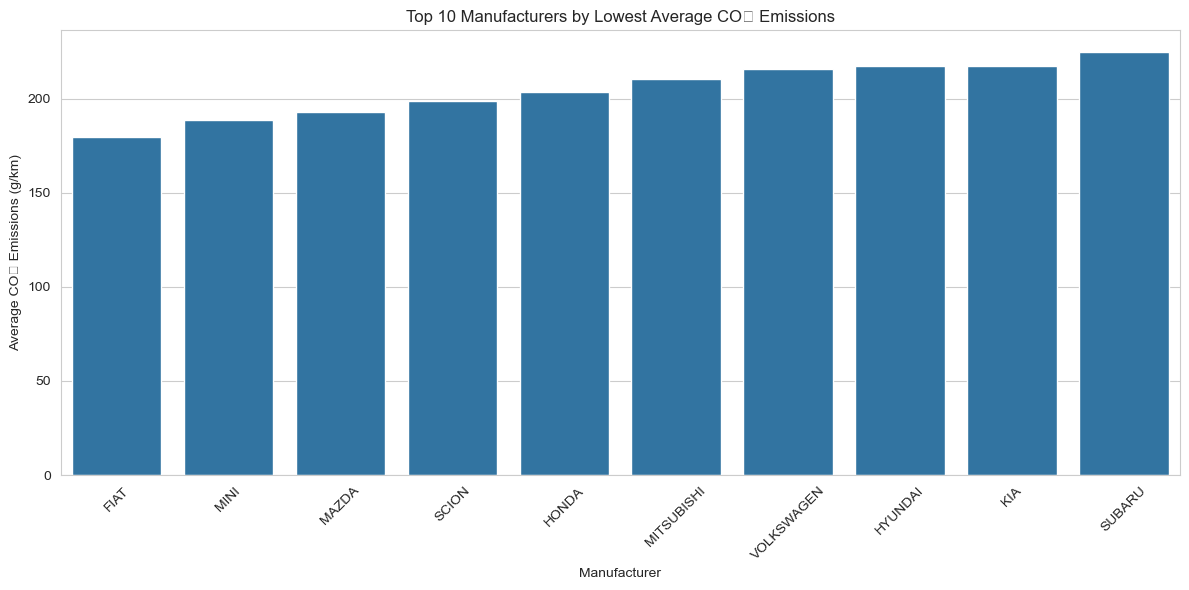

In [38]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_eco,
    x="MAKE",
    y="Average_CO2"
)

plt.title("Top 10 Manufacturers by Lowest Average CO₂ Emissions")
plt.xlabel("Manufacturer")
plt.ylabel("Average CO₂ Emissions (g/km)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Key Insights: Manufacturer Analysis (Lowest vs. Highest CO₂ Emissions)

* **Lowest Emitters (Economy & Compact Focus):** 
  * **FIAT** leads with the lowest average emissions at **179.50 g/km** (1.40 L engine, 36.3 MPG), followed closely by **MINI** (**188.53 g/km**) and **MAZDA** (**193.04 g/km**).
  * All top 10 eco-friendly brands maintain small displacements (**1.4 L – 2.5 L**) and high fuel economies (**>29.5 MPG** / **<9.8 L/100 km**).

* **Highest Emitters (Ultra-Luxury & Heavy-Duty Focus):** 
  * **ROLLS-ROYCE** averages the highest emissions at **381.00 g/km** (6.66 L engine, 17.43 MPG), followed by **BENTLEY** (**359.00 g/km**) and **ASTON MARTIN** (**351.57 g/km**).
  * High-volume truck/SUV manufacturers like **GMC** (**328.24 g/km**, 5.02 L engine) also rank among the highest carbon emitters due to large V8 powertrains.

* **Powertrain & Efficiency Divide:** 
  * The highest-emitting manufacturers produce more than **double the CO₂** of the lowest emitters (e.g., Rolls-Royce at 381 g/km vs. Fiat at 179.5 g/km).
  * High-emission brands consistently average large engine sizes (**>3.7 L**) and low fuel efficiency (**<22.9 MPG**), reflecting a clear product-line separation between economy commuters and performance/luxury/utility fleets.

In [39]:
high_emission = eligible_makes.sort_values(
    "Average_CO2",
    ascending=False
).head(10)

display(high_emission)

,MAKE,Vehicle_Count,Average_CO2,Average_Engine_Size,Average_MPG,Average_Fuel_Consumption
31,ROLLS-ROYCE,7,381.00,6.66,17.43,16.57
3,BENTLEY,8,359.00,5.35,18.25,15.60
1,ASTON MARTIN,7,351.57,5.21,18.29,15.29
12,GMC,49,328.24,5.02,17.67,16.76
23,MASERATI,6,319.67,3.70,20.33,13.90
20,LAND ROVER,19,307.84,3.79,19.84,14.96
30,RAM,13,291.23,4.15,21.54,13.57
16,JAGUAR,22,290.68,4.41,21.55,13.37
6,CADILLAC,32,287.34,4.09,22.88,12.90
25,MERCEDES-BENZ,59,277.68,4.21,24.41,12.12


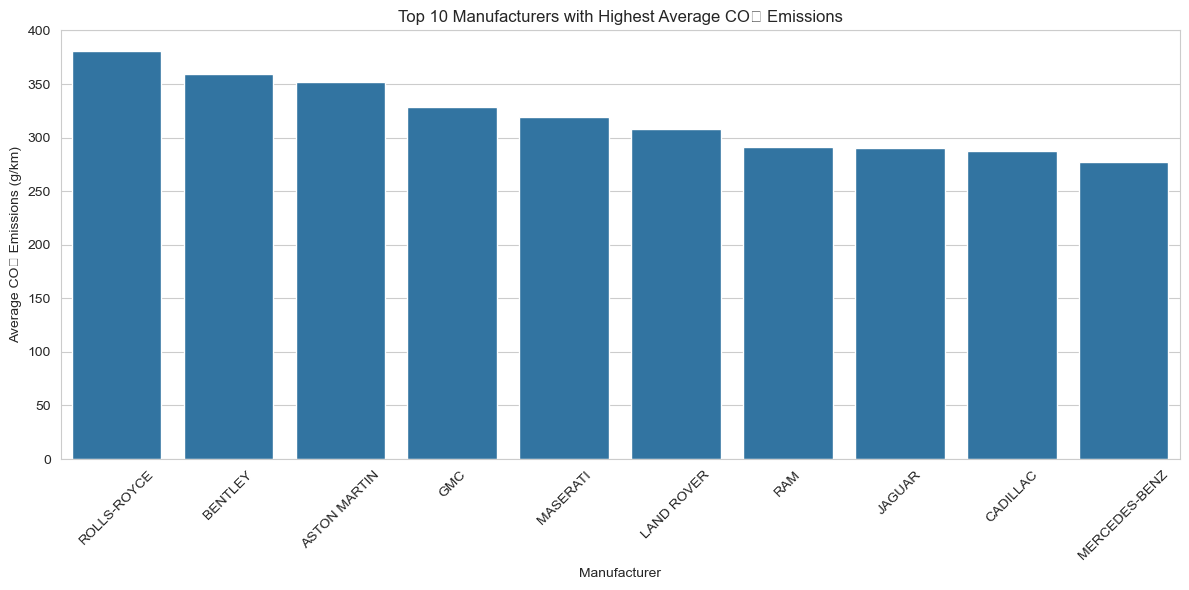

In [40]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=high_emission,
    x="MAKE",
    y="Average_CO2"
)

plt.title("Top 10 Manufacturers with Highest Average CO₂ Emissions")
plt.xlabel("Manufacturer")
plt.ylabel("Average CO₂ Emissions (g/km)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Key Insights: Top 10 Manufacturers with Highest Average CO₂ Emissions

* **Ultra-Luxury & Supercar Dominance:** **ROLLS-ROYCE** tops the list with the highest average emissions at **381.00 g/km**, followed closely by **BENTLEY** (**359.00 g/km**) and **ASTON MARTIN** (**351.57 g/km**), driven by large-displacement 12-cylinder and twin-turbo engines.
* **Heavy-Duty Commercial & Truck Presence:** **GMC** ranks 4th overall and 1st among high-volume utility brands at **328.24 g/km** (49 models, avg. 5.02 L engine), joined by **RAM** at **291.23 g/km** due to fleets dominated by V8 pickups and passenger vans.
* **Large Engine Displacement Driver:** All top 10 brands rely on high-displacement powertrains, averaging between **3.70 L** (Maserati) and **6.66 L** (Rolls-Royce).
* **Low Fuel Economy Penalty:** Poor fuel efficiency directly fuels high emission numbers—all 10 manufacturers average below **25 MPG** (spanning from **17.43 MPG** for Rolls-Royce to **24.41 MPG** for Mercedes-Benz).
* **Tier Stratification:** The top 3 exotic brands form an extreme high-emission cluster (>350 g/km), while high-end luxury/utility brands (Maserati, Land Rover, Jaguar, Cadillac, Mercedes-Benz) stabilize in the 277–320 g/km range.

In [41]:
Q1 = df["CO2EMISSIONS"].quantile(0.25)
Q3 = df["CO2EMISSIONS"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["CO2EMISSIONS"] < lower_bound) |
    (df["CO2EMISSIONS"] > upper_bound)
]

print("Number of CO₂ outliers:", len(outliers))

Number of CO₂ outliers: 6


In [42]:
top_emission_vehicles = df.sort_values(
    "CO2EMISSIONS",
    ascending=False
).head(10)

display(
    top_emission_vehicles[
        [
            "MAKE",
            "MODEL",
            "VEHICLECLASS",
            "ENGINESIZE",
            "CYLINDERS",
            "FUELTYPE",
            "CO2EMISSIONS"
        ]
    ]
)

,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,FUELTYPE,CO2EMISSIONS
349,FORD,E350 WAGON,VAN - PASSENGER,6.8,10,X,488
75,BENTLEY,MULSANNE,MID-SIZE,6.8,8,Z,437
227,CHEVROLET,EXPRESS 3500 PASSENGER,VAN - PASSENGER,6.0,8,X,435
451,GMC,SAVANA 3500 PASSENGER,VAN - PASSENGER,6.0,8,X,435
224,CHEVROLET,EXPRESS 2500 PASSENGER,VAN - PASSENGER,6.0,8,X,432
448,GMC,SAVANA 2500 PASSENGER,VAN - PASSENGER,6.0,8,X,432
633,LAMBORGHINI,AVENTADOR COUPE,TWO-SEATER,6.5,12,Z,421
350,FORD,E350 WAGON FFV,VAN - PASSENGER,5.4,8,X,421
754,MERCEDES-BENZ,G 550,SUV - STANDARD,5.5,8,Z,419
226,CHEVROLET,EXPRESS 3500 PASSENGER,VAN - PASSENGER,4.8,8,X,419


In [43]:
top_efficient = df.sort_values(
    "FUELCONSUMPTION_COMB_MPG",
    ascending=False
).head(10)

display(
    top_efficient[
        [
            "MAKE",
            "MODEL",
            "VEHICLECLASS",
            "ENGINESIZE",
            "FUELTYPE",
            "FUELCONSUMPTION_COMB_MPG",
            "CO2EMISSIONS"
        ]
    ]
)

,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,FUELTYPE,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
988,TOYOTA,PRIUS c,COMPACT,1.5,X,60,108
987,TOYOTA,PRIUS,MID-SIZE,1.8,X,59,110
487,HONDA,ACCORD HYBRID,MID-SIZE,2.0,X,59,110
1042,VOLKSWAGEN,JETTA TURBO HYBRID,COMPACT,1.4,Z,52,124
989,TOYOTA,PRIUS v,STATION WAGON - MID-SIZE,1.8,X,51,126
415,FORD,FUSION HYBRID,MID-SIZE,2.0,X,51,126
970,TOYOTA,CAMRY HYBRID LE,MID-SIZE,2.5,X,50,131
655,LEXUS,CT 200h,COMPACT,1.8,X,50,129
2,ACURA,ILX HYBRID,COMPACT,1.5,Z,48,136
342,FORD,C-MAX HYBRID,FULL-SIZE,2.0,X,47,138


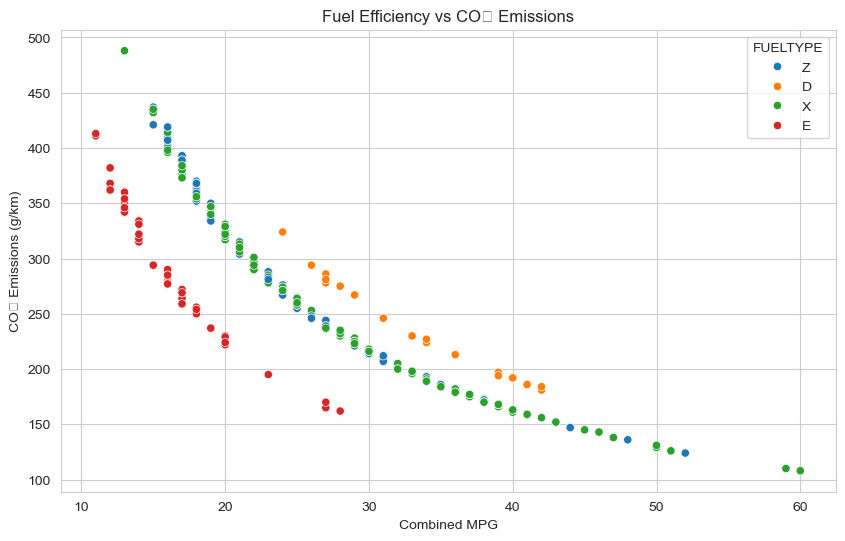

In [44]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="FUELCONSUMPTION_COMB_MPG",
    y="CO2EMISSIONS",
    hue="FUELTYPE"
)

plt.title("Fuel Efficiency vs CO₂ Emissions")
plt.xlabel("Combined MPG")
plt.ylabel("CO₂ Emissions (g/km)")

plt.show()

### Key Insights: Fuel Efficiency vs. CO₂ Emissions

* **Strong Inverse (Non-Linear) Relationship:** As fuel efficiency (`Combined MPG`) increases, CO₂ emissions drop significantly along a distinct reciprocal/hyperbolic curve (reflecting the mathematical relationship where $\text{Emissions} \propto \frac{1}{\text{MPG}}$).
* **Fuel Type Stratification:**
  * **Gasoline (`X` & `Z`):** Form the tight central curve, spanning from low-efficiency/high-emission performance trims (~15 MPG, >400 g/km) to high-efficiency hybrids (50–60 MPG, ~100–130 g/km).
  * **Diesel (`D`):** Sits slightly higher on the emissions axis for a given MPG rating compared to gasoline (~180–325 g/km across 25–40 MPG) due to the higher carbon mass per volume in diesel fuel.
  * **Ethanol / E85 (`E`):** Clusters heavily in the low MPG range (11–20 MPG) but displays lower carbon emissions for equivalent fuel burn rates compared to pure petroleum fuels.
* **Hybrid Benchmark:** The highest fuel efficiency cluster (>45 MPG) achieves the lowest emissions in the dataset (~108–138 g/km), dominated by hybrid models like the Toyota Prius, Honda Accord Hybrid, and VW Jetta Turbo Hybrid.
* **Diminishing Returns on Emission Reductions:** Improvements in the low-MPG range yield massive carbon reductions (e.g., jumping from 15 to 25 MPG cuts ~150 g/km of CO₂), whereas gains in the high-MPG range yield progressively smaller absolute carbon savings (e.g., jumping from 40 to 60 MPG cuts ~70 g/km).

## Final Business Questions
## Q1. Which vehicle class is most fuel-efficient?
Answer: COMPACT — 31.15 MPG.
## Q2. Which vehicle class is least fuel-efficient?
Answer: VAN - PASSENGER — 14.20 MPG.
## Q3. Which fuel type has lowest average emissions?
Answer: D — 227.78 g/km.
## Q4. Which fuel type has highest emissions?
Answer: E — 291.09 g/km.
## Q5. Which manufacturer is most eco-friendly?
Answer: FIAT among makes with at least 5 vehicles — 179.50 g/km.
## Q6. Which manufacturers have very high emissions?
Answer: Rolls-Royce, Bentley and Aston Martin are among the highest.
## Q7. What is the strongest factor associated with CO₂ emissions?
Answer: Combined fuel consumption shows a particularly strong positive relationship with CO₂ emissions.

# Executive Summary

The analysis of the FuelConsumption dataset reveals a strong relationship between vehicle characteristics, fuel consumption, fuel efficiency, and CO₂ emissions.

Key findings include:

1. Larger engine sizes are generally associated with higher CO₂ emissions.
2. Vehicles with more cylinders tend to have higher emissions.
3. Higher fuel consumption is strongly associated with increased CO₂ emissions.
4. Compact vehicles provide the highest average fuel efficiency.
5. Passenger vans have the lowest average fuel efficiency.
6. Fuel type D shows the lowest average CO₂ emissions.
7. Fuel type E shows the highest average CO₂ emissions.
8. FIAT has the lowest average CO₂ emissions among manufacturers with at least five vehicles.
9. Luxury/performance manufacturers with larger engines tend to have higher average emissions.
10. Higher MPG generally corresponds to lower CO₂ emissions.

## Conclusion

Overall, the analysis shows that vehicle size, engine characteristics, fuel consumption, fuel type, and vehicle class all play an important role in fuel efficiency and CO₂ emissions.

The findings can help understand which types of vehicles provide better fuel economy and which characteristics are associated with higher environmental impact.